# Evaluate RoBERTa on the Exact BABE SG2 Test Split

This notebook evaluates a **trained Hugging Face RoBERTa sequence-classification checkpoint** on the same held-out 734 examples used by the uploaded TF-IDF baseline experiment.

It uses `babe_random_split_for_roberta.csv`, where:
- `split=train` identifies the 2,935 training rows
- `split=test` identifies the 734 held-out rows
- `label_bias=0` means non-biased
- `label_bias=1` means biased

**You must point `MODEL_PATH` to your trained model checkpoint folder.** A checkpoint folder usually contains files such as `config.json`, tokenizer files, and model weights (`model.safetensors` or `pytorch_model.bin`). This notebook does not train RoBERTa; it evaluates an existing trained checkpoint.


## 1. Install dependencies
Run once in the same Python environment you use for the model.

In [7]:
%pip install -q pandas numpy scikit-learn matplotlib seaborn torch transformers

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:

from pathlib import Path
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_PATH = Path(
    r"C:\Users\ADMIN\Desktop\News Bias Detection\news-bias-detection\newsbias_roberta_best"
)

print("Folder exists:", MODEL_PATH.is_dir())
print("Config exists:", (MODEL_PATH / "config.json").is_file())
print("Weights exist:", (MODEL_PATH / "model.safetensors").is_file())

if not MODEL_PATH.is_dir():
    raise FileNotFoundError(f"Model folder not found: {MODEL_PATH}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

tokenizer = AutoTokenizer.from_pretrained(
    str(MODEL_PATH),
    local_files_only=True
)

model = AutoModelForSequenceClassification.from_pretrained(
    str(MODEL_PATH),
    local_files_only=True
)

model.to(device)
model.eval()

print("Model labels:", model.config.id2label)
print("Number of labels:", model.config.num_labels)

Folder exists: True
Config exists: True
Weights exist: True
Device: cpu


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model labels: {0: 'Non-biased', 1: 'Biased'}
Number of labels: 2


In [9]:

from transformers import AutoConfig, AutoTokenizer, AutoModelForSequenceClassification

config = AutoConfig.from_pretrained(str(MODEL_PATH))
tokenizer = AutoTokenizer.from_pretrained(str(MODEL_PATH))
model = AutoModelForSequenceClassification.from_pretrained(str(MODEL_PATH))

print("Architecture:", config.architectures)
print("Number of classes:", config.num_labels)
print("Label mapping:", config.id2label)
print("Tokenizer:", tokenizer.__class__.__name__)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Architecture: ['RobertaForSequenceClassification']
Number of classes: 2
Label mapping: {0: 'Non-biased', 1: 'Biased'}
Tokenizer: RobertaTokenizer


## 3. Load the shared split and verify its labels

In [10]:
import pandas as pd
import numpy as np

data = pd.read_csv(SPLIT_PATH)
required = {"text", "label_bias", "split"}
missing = required - set(data.columns)
if missing:
    raise ValueError(f"Missing required columns: {missing}")

data = data.dropna(subset=["text", "label_bias", "split"]).copy()
data["text"] = data["text"].astype(str)
data["label_bias"] = data["label_bias"].astype(int)
data["split"] = data["split"].astype(str).str.strip().str.lower()

train_df = data[data["split"] == "train"].reset_index(drop=True)
test_df = data[data["split"] == "test"].reset_index(drop=True)

print("Total rows:", len(data))
print("Train rows:", len(train_df))
print("Test rows:", len(test_df))
print("Label counts in test (0=non-biased, 1=biased):")
display(test_df["label_bias"].value_counts().sort_index().to_frame("count"))

assert set(data["label_bias"].unique()).issubset({0, 1}), "Unexpected label values."
assert len(test_df) > 0, "No test rows found."
assert not test_df["text"].duplicated().any(), "Duplicate texts in test set; investigate split preprocessing." 

Total rows: 3669
Train rows: 2935
Test rows: 734
Label counts in test (0=non-biased, 1=biased):


,count
label_bias,
0,373
1,361


## 4. Load the trained model and tokenizer

The model's output class IDs must match the dataset: `0=non-biased`, `1=biased`. If your training used the reverse mapping, correct it before interpreting the results.

In [11]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

tokenizer = AutoTokenizer.from_pretrained(str(MODEL_PATH))
model = AutoModelForSequenceClassification.from_pretrained(str(MODEL_PATH))
model.to(device)
model.eval()

print("Model labels:", model.config.id2label)
print("Number of labels:", model.config.num_labels)

if model.config.num_labels != 2:
    raise ValueError(f"Expected a binary classifier, found num_labels={model.config.num_labels}.")

Device: cpu


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model labels: {0: 'Non-biased', 1: 'Biased'}
Number of labels: 2


## 5. Run predictions on the exact test examples

Use the same maximum sequence length as the RoBERTa training setup when possible. If the original model was trained with `max_length=256`, keep 256 here; do not silently change this setting for the final report.

In [12]:
from torch.utils.data import Dataset, DataLoader

MAX_LENGTH = 256  # Change only if your trained model used a different max length.
BATCH_SIZE = 16

class TextDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt",
        )
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item["labels"] = torch.tensor(int(self.labels[idx]), dtype=torch.long)
        return item

test_dataset = TextDataset(
    test_df["text"], test_df["label_bias"], tokenizer, MAX_LENGTH
)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

all_logits, all_labels = [], []
with torch.no_grad():
    for batch in test_loader:
        labels = batch.pop("labels")
        batch = {k: v.to(device) for k, v in batch.items()}
        logits = model(**batch).logits
        all_logits.append(logits.detach().cpu())
        all_labels.append(labels)

logits = torch.cat(all_logits, dim=0).numpy()
y_true = torch.cat(all_labels, dim=0).numpy()
y_pred = logits.argmax(axis=1)

print("Predictions completed:", len(y_pred))

Predictions completed: 734


## 6. Metrics and confusion matrix
These metrics are computed on the same test rows as the random-split baseline.

,split,model,n_train,n_test,accuracy,macro_precision,macro_recall,macro_f1,nonbiased_f1,biased_f1
0,Random stratified (shared test rows),RoBERTa,2935,734,0.9237,0.9256,0.9232,0.9235,0.9271,0.9200


              precision    recall  f1-score   support

  non-biased     0.9013    0.9544    0.9271       373
      biased     0.9499    0.8920    0.9200       361

    accuracy                         0.9237       734
   macro avg     0.9256    0.9232    0.9235       734
weighted avg     0.9252    0.9237    0.9236       734



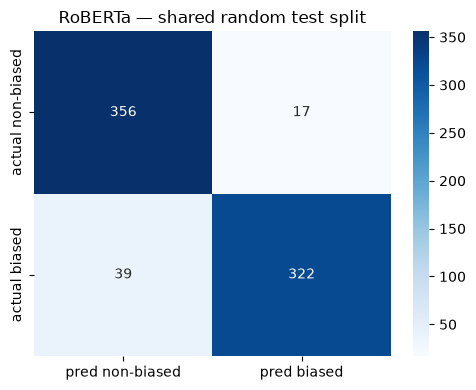

In [13]:
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, f1_score
)
import matplotlib.pyplot as plt
import seaborn as sns

macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, labels=[0, 1], average="macro", zero_division=0
)
roberta_result = pd.DataFrame([{
    "split": "Random stratified (shared test rows)",
    "model": "RoBERTa",
    "n_train": len(train_df),
    "n_test": len(test_df),
    "accuracy": accuracy_score(y_true, y_pred),
    "macro_precision": macro_p,
    "macro_recall": macro_r,
    "macro_f1": macro_f1,
    "nonbiased_f1": f1_score(y_true, y_pred, pos_label=0, zero_division=0),
    "biased_f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
}])

display(roberta_result.style.format({
    "accuracy": "{:.4f}", "macro_precision": "{:.4f}", "macro_recall": "{:.4f}",
    "macro_f1": "{:.4f}", "nonbiased_f1": "{:.4f}", "biased_f1": "{:.4f}"
}))

print(classification_report(
    y_true, y_pred, labels=[0, 1],
    target_names=["non-biased", "biased"], digits=4, zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["pred non-biased", "pred biased"],
            yticklabels=["actual non-biased", "actual biased"], ax=ax)
ax.set_title("RoBERTa — shared random test split")
plt.tight_layout()
plt.show()

## 7. Compare RoBERTa directly with the baseline CSV
This combines only the random-split rows from the TF-IDF results file with the RoBERTa result computed above.

In [14]:
BASELINE_RESULTS_PATH = Path("babe_baseline_comparison_results.csv")

if BASELINE_RESULTS_PATH.exists():
    baseline = pd.read_csv(BASELINE_RESULTS_PATH)
    random_baseline = baseline[baseline["split"].astype(str).str.lower().eq("random stratified")].copy()
    comparison = pd.concat([random_baseline, roberta_result], ignore_index=True)
    display(comparison[[
        "split", "model", "n_train", "n_test", "accuracy", "macro_f1",
        "nonbiased_f1", "biased_f1"
    ]].style.format({
        "accuracy": "{:.4f}", "macro_f1": "{:.4f}",
        "nonbiased_f1": "{:.4f}", "biased_f1": "{:.4f}"
    }))
    comparison.to_csv("babe_roberta_vs_baselines_shared_test.csv", index=False)
    print("Saved: babe_roberta_vs_baselines_shared_test.csv")
else:
    print("Baseline results CSV not found. Copy babe_baseline_comparison_results.csv here to create the comparison table.")

,split,model,n_train,n_test,accuracy,macro_f1,nonbiased_f1,biased_f1
0,Random stratified,TF-IDF + Logistic Regression,2935,734,0.7302,0.7301,0.7235,0.7367
1,Random stratified,TF-IDF + Linear SVM,2935,734,0.7153,0.7151,0.7085,0.7217
2,Random stratified (shared test rows),RoBERTa,2935,734,0.9237,0.9235,0.9271,0.9200


Saved: babe_roberta_vs_baselines_shared_test.csv


## 8. Save test predictions for error analysis

Use the output to inspect examples RoBERTa gets wrong. Error analysis is a strong next step for the project report.

In [15]:
predictions_df = test_df[["text", "label_bias"]].copy()
predictions_df["predicted_label"] = y_pred
predictions_df["correct"] = predictions_df["label_bias"] == predictions_df["predicted_label"]
predictions_df["true_label_name"] = predictions_df["label_bias"].map({0: "non-biased", 1: "biased"})
predictions_df["predicted_label_name"] = predictions_df["predicted_label"].map({0: "non-biased", 1: "biased"})

predictions_df.to_csv("roberta_shared_test_predictions.csv", index=False)
print("Saved: roberta_shared_test_predictions.csv")
print("Misclassified examples:", int((~predictions_df["correct"]).sum()))
display(predictions_df[~predictions_df["correct"]].head(25))

Saved: roberta_shared_test_predictions.csv
Misclassified examples: 56


,text,label_bias,predicted_label,correct,true_label_name,predicted_label_name
23,A trio of polls released ahead of Wednesday’s ...,1,0,False,biased,non-biased
36,"Alex Berenson, a former reporter at the New Yo...",1,0,False,biased,non-biased
60,"Antifa, short for “anti-fascist,” is an amorph...",0,1,False,non-biased,biased
76,As the president spoke about doing “a lot” to ...,1,0,False,biased,non-biased
87,"Biden seemed to get this, arguing, ""We can arg...",0,1,False,non-biased,biased
88,Biden spoke passionately Saturday night about ...,1,0,False,biased,non-biased
98,But even those who take steps to better their ...,1,0,False,biased,non-biased
114,But Trump’s pro-American policies are frustrat...,1,0,False,biased,non-biased
173,Experts have warned that a total U.S. withdraw...,1,0,False,biased,non-biased
178,Few would consider a global pandemic reason to...,1,0,False,biased,non-biased


## Final checklist before reporting

- Confirm the checkpoint was trained with `0=non-biased`, `1=biased`.
- Use the same test rows and preprocessing as the baseline.
- Set `MAX_LENGTH` to the value used during training.
- Report accuracy, macro-F1, and per-class precision/recall/F1.
- Do not claim the result beats the old 81.97% report score unless that older model is evaluated on this same test split.
- Include error analysis and mention limitations: dataset size, expert-label subjectivity, outlet shift, and sentence-level scope.
